## Peta capaian harian ↔ sel notebook


| Capaian | Isi | Sel di notebook |
|---|---|---|
| **H1** | Unduh ZIP + CSV Bug Bytes dan CSV getaran USDA | Sel parameter (folder `RAW`), sel memuat CSV USDA |
| **H2–3** | Pilih file hama gudang dan noise, cek `fs`, resample | Sel parameter (`META`, `NOISE_BB`, `ESC_KELAS`), fungsi dasar (`baca_wav`, `resample_ke`), diagnostik noise, kolam noise |
| **H4–5** | Skrip highpass, RMS, dan deteksi event | Sel fungsi dasar (`highpass`, `rms_frame`, `deteksi_event`) |
| **H6–7** | Profil RMS, event, pita dominan per spesies dan sensor | Sel profil per file, grafik spektrum |
| **H8–9** | Campur noise 4 SNR × 20 potongan, spectral subtraction | Sel fungsi SNR/SS, eksperimen utama, ringkasan & kurva |
| **H10** | Kruskal–Wallis, Wilcoxon, Spearman (CSV USDA) | Sel Kruskal–Wallis (+Dunn), Wilcoxon, Kruskal–Wallis + Spearman USDA |

In [1]:
# ---------------- 1) IMPOR PUSTAKA ----------------
import glob, os, re, json, time   
from fractions import Fraction    
import numpy as np                
import pandas as pd               
import matplotlib.pyplot as plt   
import scipy                      
from scipy import stats           
from scipy.io import wavfile      
from scipy.signal import butter, sosfiltfilt, resample_poly, stft, istft, welch


# ---------------- 2) LOKASI FOLDER ----------------
RAW  = "../data/raw"                 
BIRD = "../data/bird_sounds"          
RES  = "../results"                   
os.makedirs(RES, exist_ok=True)       

# ---------------- 3) PARAMETER  ----------------
FS_BERSAMA = 20000     
HP_HZ      = 200       
FRAME_S    = 0.01      
K_MAD      = 3         
SNR_LIST   = [-5, 0, 5, 10]   
N_POTONG   = 20        # jumlah potongan noise acak untuk setiap tingkat SNR
ALPHAS     = [1.0, 2.0]  
BETA       = 0.01     
NPERSEG, NOVERLAP = 1024, 768    
QUIET_PCT  = 20        
SEED       = 42        
ALPHA_SIG  = 0.05      

# ---------------- 4) PILIHAN FILE NOISE ----------------
# noise Bug Bytes (rekaman akselerometer, kategori I; I5/I7 dibuang karena ada larva)
NOISE_BB = ["I3", "I4", "I6"]

#kelas noise Topik 1 (nomor kelas menurut urutan ESC-50). Verifikasi dengan mendengarkan klipnya.
ESC_KELAS    = {10: "hujan", 44: "mesin", 30: "ketukan pintu"}  
ESC_KATEGORI = ["training"]     
ESC_KLIP_MAKS = 40              

# ---------------- 5) PILIHAN FILE HAMA ----------------
META = {
    "A3": ("hama", "S. oryzae", "PVDF",              "larva dalam gandum"),
    "A4": ("hama", "S. oryzae", "akselerometer",     "larva dalam gandum"),
    "A5": ("hama", "S. oryzae", "ultrasonik 40 kHz", "larva dalam gandum"),
    "A6": ("hama", "S. oryzae", "ultrasonik 30 kHz", "larva dalam gandum"),
    "A7": ("hama", "S. oryzae", "piezoelektrik",     "larva dalam gandum"),
    "A8": ("hama", "S. zeamais", "mikrofon",         "larva dalam jagung"),
    "A9": ("hama", "S. zeamais", "mikrofon",         "dewasa dalam jagung"),
}

print("python libs -> numpy", np.__version__, "| scipy", scipy.__version__, "| pandas", pd.__version__)
print("parameter siap")

python libs -> numpy 2.5.4 | scipy 1.18.1 | pandas 3.1.0
parameter siap


## Fungsi baca WAV, resample, highpass, RMS, dan deteksi event
*H2–3: cek `fs`, resample (`baca_wav`, `resample_ke`).*
*H4–5: skrip highpass, RMS, dan deteksi event (`highpass`, `proses`, `rms_frame`, `deteksi_event`).*
*Fungsi pendukung: `fitur_event` (dipakai H6–7), `cari_file`, dan `rank_biserial` (ukuran efek uji Wilcoxon, H10).*

In [2]:
# =====================================================================
# KUMPULAN FUNGSI DASAR 
# =====================================================================

def baca_wav(path):
    """Membaca satu file WAV.
    Masukan : path file.
    Keluaran: (fs, x) -> fs = laju sampling (Hz), x = sinyal sebagai array float
              yang sudah dikurangi rata-rata (offset DC dibuang)."""
    fs, x = wavfile.read(path)       # fs = sampel per detik; x = nilai amplitudo mentah (integer)
    x = x.astype(float)              # ubah ke desimal supaya hitungan tidak terpotong/meluap
    if x.ndim > 1:                   # bila stereo (2 kolom)...
        x = x.mean(axis=1)           # ...jadikan mono dengan merata-ratakan kedua kanal
    return fs, x - x.mean()          # kurangi rata-rata -> sinyal berpusat di nol

def resample_ke(x, fs, fs_baru):
    """Mengubah laju sampling dari fs ke fs_baru (capaian H2-3)."""
    if fs == fs_baru:                # sudah sama -> tidak perlu diubah
        return x
    r = Fraction(fs_baru, fs)        # rasio sebagai pecahan eksak, mis. 20000/44100 = 200/441
    return resample_poly(x, r.numerator, r.denominator)   # naikkan x pembilang, turunkan x penyebut, dengan filter anti-aliasing

def highpass(x, fs, fc=HP_HZ, order=4):
    """Filter highpass Butterworth orde 4: membuang frekuensi di bawah fc (capaian H4-5)."""
    sos = butter(order, fc, btype="highpass", fs=fs, output="sos")   # rancang filter; bentuk 'sos' (second-order sections) lebih stabil secara numerik
    return sosfiltfilt(sos, x)       # terapkan maju lalu mundur (zero-phase): bentuk gelombang tidak bergeser waktunya

def proses(x, fs):
    """Praproses lengkap satu sinyal: resample -> highpass."""
    # urutan praproses: resample -> highpass
    return highpass(resample_ke(x, fs, FS_BERSAMA), FS_BERSAMA)

def rms_frame(x, fs=FS_BERSAMA, frame_s=FRAME_S):
    """Menghitung RMS (akar rata-rata kuadrat = ukuran 'kekuatan' sinyal) tiap frame 10 ms (capaian H4-5)."""
    n = int(round(fs * frame_s))                         # jumlah sampel per frame (20000 x 0,01 = 200 sampel)
    m = len(x) // n                                      # jumlah frame utuh (sisa di ujung dibuang)
    return np.sqrt((x[:m * n].reshape(m, n) ** 2).mean(axis=1))   # susun jadi (m frame x n sampel) -> kuadratkan -> rata-ratakan per frame -> akar

def deteksi_event(rms, frame_s=FRAME_S, k=K_MAD):
    """Mendeteksi 'event' (getaran/gigitan hama) = rentang frame yang RMS-nya melewati ambang.
    Ambang = median + k x MAD (kebal terhadap pencilan dibanding rata-rata + simpangan baku).
    Keluaran: (tabel event, nilai ambang)."""
    med = np.median(rms)                                 # nilai tengah RMS = perkiraan tingkat latar
    mad = np.median(np.abs(rms - med))                   # MAD: median selisih mutlak terhadap median
    ambang = med + k * mad                               # batas di atasnya dianggap event
    aktif = rms > ambang                                 # True/False tiap frame: di atas ambang atau tidak
    d = np.diff(np.concatenate([[0], aktif.astype(int), [0]]))   # selisih berurutan: +1 = awal event, -1 = akhir event (0 di kedua ujung sebagai pengaman)
    mulai, akhir = np.where(d == 1)[0], np.where(d == -1)[0]     # nomor frame awal dan akhir tiap event
    ev = pd.DataFrame({"f_mulai": mulai, "f_akhir": akhir})      # tabel event berisi indeks frame
    ev["mulai_s"] = ev.f_mulai * frame_s                 # waktu mulai (detik)
    ev["akhir_s"] = ev.f_akhir * frame_s                 # waktu selesai (detik)
    ev["durasi_ms"] = (ev.akhir_s - ev.mulai_s) * 1000   # lama event (milidetik)
    ev["jeda_ke_berikut_s"] = ev.mulai_s.shift(-1) - ev.akhir_s   # jarak ke event berikutnya (detik)
    return ev, ambang

def fitur_event(y, fs, ev, rms, nfft=2048):
    """Menghitung fitur tiap event (capaian H6-7): durasi, kekuatan, frekuensi dominan, dan centroid spektral.
    rasio_dB = RMS event dibanding RMS latar (median RMS frame) -> tidak bergantung skala/gain sensor."""
    latar = max(np.median(rms), 1e-12)                   # RMS latar; batas 1e-12 mencegah pembagian dengan nol
    f = np.fft.rfftfreq(nfft, 1 / fs)                    # sumbu frekuensi (Hz) untuk FFT berukuran nfft
    baris = []                                           # penampung hasil tiap event
    for r in ev.itertuples():                            # ulangi untuk setiap event
        seg = y[int(r.mulai_s * fs): int(r.akhir_s * fs)]   # potong sinyal pada rentang waktu event
        if len(seg) < 8:                                 # terlalu pendek untuk dianalisis -> lewati
            continue
        P = np.abs(np.fft.rfft(seg * np.hanning(len(seg)), n=nfft)) ** 2   # spektrum daya: jendela Hann -> FFT -> kuadrat besaran
        if P.sum() == 0:                                 # tidak ada energi -> lewati
            continue
        er = float(np.sqrt(np.mean(seg ** 2)))           # RMS event
        baris.append({"durasi_ms": r.durasi_ms, "rms_abs": er,
                      "rasio_dB": 20 * np.log10(er / latar + 1e-12),     # rasio event/latar dalam desibel
                      "f_dom_Hz": float(f[P.argmax()]),                  # frekuensi dominan = frekuensi dengan daya terbesar
                      "centroid_Hz": float((f * P).sum() / P.sum())})    # centroid = "pusat massa" spektrum (rata-rata frekuensi berbobot daya)
    return pd.DataFrame(baris)

def cari_file(kode):
    """Mencari file WAV berawalan kode (mis. 'A3' -> '../data/raw/A3-xxxx.wav'); None bila tidak ada."""
    c = sorted(glob.glob(f"{RAW}/{kode}-*.wav"))         # semua file yang cocok pola, diurutkan
    return c[0] if c else None                           # ambil yang pertama

def rank_biserial(d):
    """Ukuran efek (-1..+1) untuk uji Wilcoxon berpasangan: +1 = hampir semua selisih positif, -1 = hampir semua negatif."""
    d = np.asarray(d, float); d = d[d != 0]              # selisih nol tidak ikut dihitung
    if len(d) == 0:
        return np.nan
    r = stats.rankdata(np.abs(d))                        # peringkat dari besar selisih (tanpa tanda)
    wp, wm = r[d > 0].sum(), r[d < 0].sum()              # jumlah peringkat selisih positif (wp) dan negatif (wm)
    return (wp - wm) / (wp + wm)                         # rank-biserial = (W+ - W-) / (W+ + W-)

print("fungsi siap")

fungsi siap



**Alur praproses satu rekaman:** `baca_wav` → `resample_ke` → `highpass` (digabung di `proses`) → `rms_frame` → `deteksi_event` → `fitur_event`.

| Fungsi | Apa yang dilakukan | Mengapa perlu |
|---|---|---|
| `baca_wav` | Membaca WAV, menjadikannya mono, membuang offset rata-rata | Sinyal mentah bisa stereo dan tidak berpusat di nol |
| `resample_ke` | Menyeragamkan `fs` ke 20 kHz dengan `resample_poly` | Sensor berbeda punya `fs` berbeda; analisis harus pada skala waktu yang sama |
| `highpass` | Butterworth orde 4, 200 Hz, `sosfiltfilt` | Membuang getaran lambat/dengung di bawah 200 Hz yang bukan sinyal hama; `sosfiltfilt` memfilter dua arah sehingga posisi event di waktu tidak bergeser |
| `rms_frame` | RMS per frame 10 ms | Mengubah sinyal 20.000 titik/detik menjadi “profil kekuatan” 100 titik/detik |
| `deteksi_event` | Ambang median + 3·MAD, lalu mencari rentang frame di atas ambang | Menentukan kapan hama bersuara; median/MAD dipilih karena tidak terganggu oleh event itu sendiri |
| `fitur_event` | Durasi, RMS, rasio terhadap latar (dB), frekuensi dominan (FFT), centroid | Ringkasan numerik tiap event untuk dibandingkan antar spesies/sensor |
| `cari_file` | Mencari WAV dari kode (mis. `A3`) | Menghubungkan `META` dengan file nyata |
| `rank_biserial` | Ukuran efek dari selisih berpasangan | Uji Wilcoxon hanya memberi p-value; ukuran efek menunjukkan *seberapa besar* bedanya |

**Catatan istilah:** *RMS* = akar dari rata-rata kuadrat amplitudo; *MAD* = median selisih mutlak dari median; *FFT* = penguraian sinyal menjadi frekuensi-frekuensi penyusunnya.

## Profil RMS dan event per spesies dan sensor
*H6–7: profil RMS, event, dan pita dominan per spesies dan sensor.* Sel ini menjalankan seluruh praproses untuk **setiap file hama** di `META` dan menyimpan tabel ringkasnya.

In [3]:
# =====================================================================
# Memproses SEMUA file hama di META: baca -> praproses -> RMS -> event -> fitur
# =====================================================================
hasil, fitur_semua, ringkas = {}, [], []   # hasil: sinyal & event per kode | fitur_semua: tabel fitur event | ringkas: ringkasan per file
fs_min = []                                # mencatat fs asli tiap file (untuk memeriksa FS_BERSAMA)
for kode, (peran, spesies, sensor, ket) in META.items():   # ulangi untuk A3, A4, ..., A9
    p = cari_file(kode)                                    # cari file WAV-nya
    if p is None:                                          # tidak ketemu -> beri peringatan, lanjut ke file berikutnya
        print(f"[!] {kode}: file tidak ditemukan di {RAW}")
        continue
    fs, x = baca_wav(p)                                    # baca sinyal mentah dan fs aslinya
    fs_min.append(fs)                                      # simpan fs asli untuk pemeriksaan di bawah
    y = proses(x, fs)                                      # resample ke 20 kHz lalu highpass 200 Hz
    rms = rms_frame(y)                                     # profil RMS per 10 ms
    ev, ambang = deteksi_event(rms)                        # deteksi event dan ambangnya
    ft = fitur_event(y, FS_BERSAMA, ev, rms)               # fitur tiap event (durasi, rasio dB, frekuensi dominan, centroid)
    ft.insert(0, "kode", kode); ft.insert(1, "spesies", spesies); ft.insert(2, "sensor", sensor)   # tambah kolom identitas di depan tabel
    fitur_semua.append(ft)                                 # kumpulkan untuk digabung nanti
    hasil[kode] = dict(y=y, rms=rms, ev=ev, ambang=ambang, fs_asal=fs)   # simpan semua hasil antara (dipakai sel berikutnya)
    dur = len(y) / FS_BERSAMA                              # durasi rekaman (detik)
    ringkas.append({"kode": kode, "spesies": spesies, "sensor": sensor, "ket": ket,
                    "fs_asal": fs, "durasi_s": round(dur, 1), "n_event": len(ev),
                    "laju_event_per_s": round(len(ev) / dur, 2),                  # event per detik
                    "median_durasi_ms": round(ft.durasi_ms.median(), 1) if len(ft) else None,
                    "median_rasio_dB": round(ft.rasio_dB.median(), 1) if len(ft) else None,
                    "median_f_dom_Hz": round(ft.f_dom_Hz.median()) if len(ft) else None,          # pita dominan (median)
                    "median_centroid_Hz": round(ft.centroid_Hz.median()) if len(ft) else None})

assert len(hasil) > 0, "tidak ada file hama yang terbaca"   # hentikan bila tak satu pun file terbaca
assert FS_BERSAMA <= min(fs_min), f"FS_BERSAMA ({FS_BERSAMA}) > fs terkecil ({min(fs_min)}): akan terjadi upsampling"   # pastikan tidak ada upsampling
fitur_df = pd.concat(fitur_semua, ignore_index=True)       # gabungkan fitur semua file jadi satu tabel besar
fitur_df.to_csv(f"{RES}/m2_fitur_event.csv", index=False)  # simpan: satu baris = satu event
profil = pd.DataFrame(ringkas)                             # tabel ringkasan satu baris per file
profil.to_csv(f"{RES}/m2_profil_per_file.csv", index=False)
profil                                                     # tampilkan tabel (nilai terakhir sel otomatis ditampilkan)

,kode,spesies,sensor,ket,fs_asal,durasi_s,n_event,laju_event_per_s,median_durasi_ms,median_rasio_dB,median_f_dom_Hz,median_centroid_Hz
0,A3,S. oryzae,PVDF,larva dalam gandum,25000,10.0,106,10.60,10.0,3.2,6685,5792
1,A4,S. oryzae,akselerometer,larva dalam gandum,25000,10.0,123,12.30,10.0,3.9,1514,3800
2,A5,S. oryzae,ultrasonik 40 kHz,larva dalam gandum,50000,10.0,49,4.90,10.0,1.4,6807,5812
3,A6,S. oryzae,ultrasonik 30 kHz,larva dalam gandum,50000,10.0,35,3.50,10.0,1.2,7168,5772
4,A7,S. oryzae,piezoelektrik,larva dalam gandum,25000,10.0,105,10.50,10.0,9.6,2266,3463
5,A8,S. zeamais,mikrofon,larva dalam jagung,20000,20.9,80,3.83,10.0,3.0,693,3531
6,A9,S. zeamais,mikrofon,dewasa dalam jagung,20000,18.7,175,9.36,10.0,7.7,557,1027




**Dua tabel keluaran**
- `fitur_df` / `m2_fitur_event.csv`: **satu baris = satu event**, dipakai sebagai data uji statistik (Kruskal–Wallis).
- `profil` / `m2_profil_per_file.csv`: **satu baris = satu file**. Kolom `laju_event_per_s` (aktivitas), `median_durasi_ms`, `median_rasio_dB` (seberapa menonjol dibanding latar), dan `median_f_dom_Hz` / `median_centroid_Hz` (**pita dominan**) merangkum karakter tiap spesies dan sensor.

**Pemeriksaan keamanan.** Dua `assert` memastikan ada file yang terbaca dan `FS_BERSAMA` tidak lebih besar daripada `fs` asli terkecil (menghindari *upsampling*).

## Spektrum rata-rata (pita dominan) tiap file

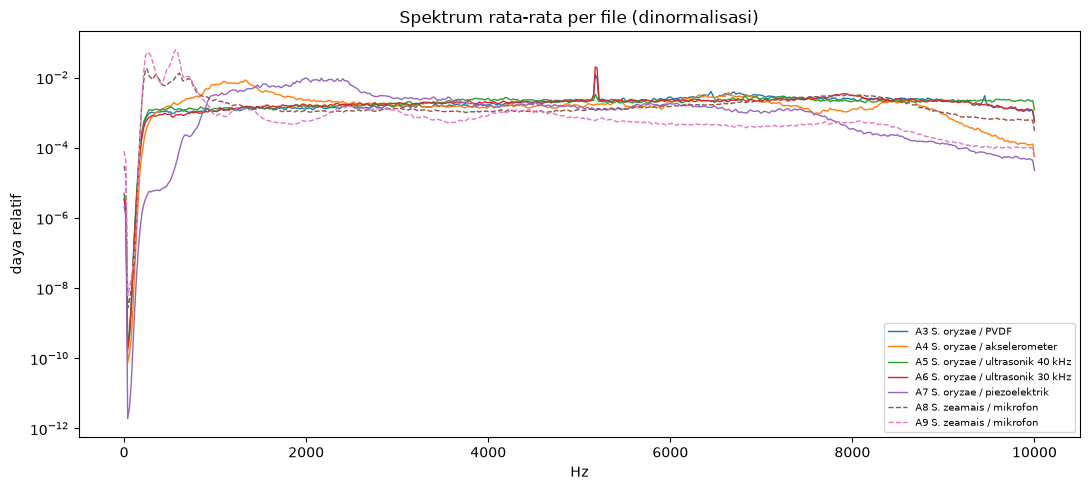

In [4]:
# spektrum rata-rata (Welch, Hann 1024) per file, dinormalisasi supaya bentuknya bisa dibandingkan
fig, ax = plt.subplots(figsize=(11, 5))                    # siapkan kanvas grafik satu panel
for kode, h in hasil.items():                              # satu kurva untuk tiap file hama
    f, Pxx = welch(h["y"], FS_BERSAMA, window="hann", nperseg=1024)   # metode Welch: sinyal dipotong-potong 1024 sampel, dijendela Hann, spektrumnya dirata-ratakan
    ls = "-" if META[kode][1] == "S. oryzae" else "--"     # garis penuh untuk S. oryzae, putus-putus untuk S. zeamais
    ax.semilogy(f, Pxx / Pxx.sum(), ls, lw=1, label=f"{kode} {META[kode][1]} / {META[kode][2]}")   # sumbu y logaritmik; daya dibagi totalnya agar bentuk antar sensor sebanding
ax.set(title="Spektrum rata-rata per file (dinormalisasi)", xlabel="Hz", ylabel="daya relatif")   # judul dan label sumbu
ax.legend(fontsize=7)                                      # legenda kecil
fig.tight_layout()                                         # rapikan tata letak
fig.savefig(f"{RES}/m2_spektrum_per_file.png", dpi=150)    # simpan gambar ke folder results
plt.show(); plt.close(fig)                                 # tampilkan lalu tutup agar memori tidak menumpuk



**Mengapa dinormalisasi.** Tiap sensor punya skala amplitudo berbeda. Dengan membagi daya terhadap totalnya, yang dibandingkan hanyalah **bentuk** spektrum, bukan kerasnya sinyal.

**Metode Welch** membagi sinyal menjadi potongan 1024 sampel, menerapkan jendela Hann, lalu merata-ratakan spektrumnya, sehingga kurva lebih halus dan tidak terlalu berisik dibanding FFT tunggal. Garis penuh = *S. oryzae*, putus-putus = *S. zeamais*.

## Perbedaan antar spesies dan antar sensor (Kruskal–Wallis + Dunn)

Unit analisis = **event**. Fitur yang diuji: durasi event, `rasio_dB` (RMS event dibanding latar, supaya tidak bergantung gain tiap sensor), frekuensi dominan, dan spectral centroid. Ukuran efek: ε² (epsilon kuadrat).



## Kruskal–Wallis (+ Dunn) antar spesies dan sensor
*uji Kruskal–Wallis pada fitur event.*

,faktor,fitur,n_grup,n_event,H,p,epsilon2,signifikan
0,spesies,durasi_ms,2,673,39.48,3.312322e-10,0.059,True
1,spesies,rasio_dB,2,673,31.53,1.959837e-08,0.047,True
2,spesies,f_dom_Hz,2,673,302.81,8.048591e-68,0.451,True
3,spesies,centroid_Hz,2,673,277.77,2.304503e-62,0.413,True
4,sensor,durasi_ms,6,673,43.69,2.682502e-08,0.065,True
5,sensor,rasio_dB,6,673,296.37,6.031611e-62,0.441,True
6,sensor,f_dom_Hz,6,673,394.35,4.908772e-83,0.587,True
7,sensor,centroid_Hz,6,673,399.75,3.361283e-84,0.595,True


[!] Dunn butuh scikit-posthocs: jalankan  pip install scikit-posthocs  lalu ulangi sel ini


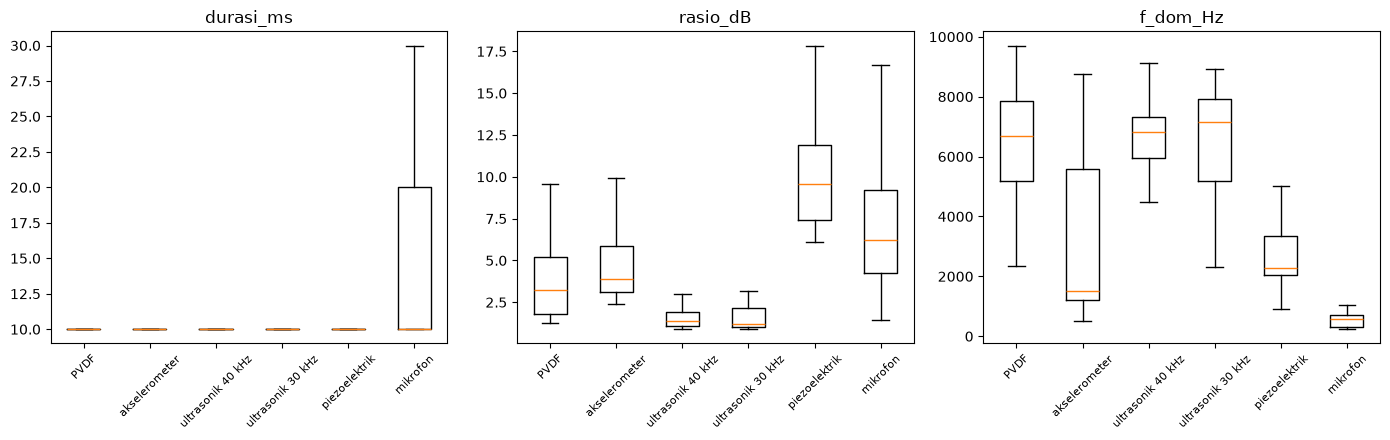

In [5]:
# =====================================================================
# Uji Kruskal-Wallis: apakah fitur event berbeda antar spesies / antar sensor?
# =====================================================================
FITUR = ["durasi_ms", "rasio_dB", "f_dom_Hz", "centroid_Hz"]   # fitur yang diuji
MIN_PER_GRUP = 5                                               # grup dengan event < 5 tidak ikut uji (terlalu sedikit)

def kruskal_es(grups):
    """Kruskal-Wallis + ukuran efek epsilon-kuadrat.
    Masukan : daftar array (satu array per grup). Keluaran: (H, p, epsilon^2)."""
    H, p = stats.kruskal(*grups)                 # statistik H dan p-value (uji non-parametrik pengganti ANOVA, berbasis peringkat)
    n = sum(len(g) for g in grups)            
    return H, p, H * (n + 1) / (n ** 2 - 1)      # epsilon^2 = H(n+1)/(n^2-1): proporsi variasi peringkat yang dijelaskan oleh grup

baris = []                                       # penampung baris hasil
for faktor in ["spesies", "sensor"]:             # dua pengelompokan: per spesies, lalu per sensor
    kel = {k: g for k, g in fitur_df.groupby(faktor) if len(g) >= MIN_PER_GRUP}   # kelompokkan event; buang grup yang terlalu kecil
    dibuang = sorted(set(fitur_df[faktor]) - set(kel))   # daftar grup yang dibuang (untuk dilaporkan)
    if dibuang:
        print(f"[!] {faktor}: grup dibuang (event < {MIN_PER_GRUP}): {dibuang}")
    if len(kel) < 2:                             # uji butuh minimal 2 grup
        print(f"[!] {faktor}: kurang dari 2 grup, uji dilewati")
        continue
    for ft in FITUR:                             # uji tiap fitur secara terpisah
        H, p, e2 = kruskal_es([g[ft].values for g in kel.values()])
        baris.append({"faktor": faktor, "fitur": ft, "n_grup": len(kel), "n_event": sum(len(g) for g in kel.values()),
                      "H": round(H, 2), "p": p, "epsilon2": round(e2, 3), "signifikan": p < ALPHA_SIG})
h1 = pd.DataFrame(baris)                         
h1.to_csv(f"{RES}/m2_h1_kruskal.csv", index=False)
display(h1)                                      

# post-hoc Dunn (Holm) antar sensor: Kruskal-Wallis hanya bilang "ada beda", Dunn menunjuk PASANGAN mana yang beda
try:
    import scikit_posthocs as sp                 # pustaka tambahan untuk uji lanjutan
    d_sens = fitur_df[fitur_df.groupby("sensor")["sensor"].transform("size") >= MIN_PER_GRUP]   # hanya sensor dengan event cukup
    for ft in FITUR:
        dunn = sp.posthoc_dunn(d_sens, val_col=ft, group_col="sensor", p_adjust="holm")   # p-value semua pasangan sensor, dikoreksi Holm (menahan kesalahan akibat banyak perbandingan)
        dunn.to_csv(f"{RES}/m2_h1_dunn_sensor_{ft}.csv")
    print("Dunn disimpan: m2_h1_dunn_sensor_<fitur>.csv ; contoh (rasio_dB):")
    display(pd.read_csv(f"{RES}/m2_h1_dunn_sensor_rasio_dB.csv", index_col=0).round(4))
except ImportError:                              # pustaka belum terpasang -> beri petunjuk, jangan crash
    print("[!] Dunn butuh scikit-posthocs: jalankan  pip install scikit-posthocs  lalu ulangi sel ini")

# gambar sebaran fitur per sensor
fig, ax = plt.subplots(1, 3, figsize=(14, 4.5))  # tiga panel berdampingan
urut = list(fitur_df["sensor"].unique())         # urutan sensor di sumbu-x
for a, ft in zip(ax, ["durasi_ms", "rasio_dB", "f_dom_Hz"]):
    a.boxplot([fitur_df.loc[fitur_df.sensor == s, ft] for s in urut], showfliers=False)   # boxplot per sensor; pencilan tidak digambar
    a.set_xticks(range(1, len(urut) + 1)); a.set_xticklabels(urut, rotation=45, fontsize=8)   # kompatibel semua versi matplotlib
    a.set_title(ft)
fig.tight_layout()
fig.savefig(f"{RES}/m2_h1_fitur_per_sensor.png", dpi=150)
plt.show(); plt.close(fig)

### Penjelasan uji Kruskal–Wallis dan Dunn

**Mengapa Kruskal–Wallis.** Fitur event tidak berdistribusi normal dan ukuran grup berbeda-beda, jadi dipakai uji **non-parametrik berbasis peringkat** (pengganti ANOVA satu arah). Hasil `p < 0,05` berarti minimal satu grup berbeda.

**Ukuran efek ε².** p-value saja tidak menunjukkan seberapa besar bedanya (dengan banyak event, beda kecil pun bisa signifikan). ε² berkisar 0–1: makin mendekati 1, makin besar pengaruh grup terhadap fitur.

**Post-hoc Dunn (koreksi Holm).** Kruskal–Wallis tidak menyebut *grup mana* yang berbeda. Uji Dunn membandingkan setiap pasangan sensor, dan koreksi Holm menjaga agar banyaknya perbandingan tidak memperbesar peluang salah mendeteksi beda.



## Diagnostik energi spektrum noise (memilih file noise)
*H2–3: pilih file noise, cek `fs`. Sel ini membantu memastikan kelas noise ESC-50 yang dipilih masih punya energi setelah highpass.*

In [6]:
# =====================================================================
# Diagnostik: seberapa banyak energi tiap kelas noise ESC-50 yang akan hilang oleh highpass 200 Hz?
# =====================================================================
# Daftar nama 50 kelas ESC-50 sesuai urutan standar (indeks 0..49). Dipakai untuk menerjemahkan nomor kelas -> nama.
ESC50 = ["dog","rooster","pig","cow","frog","cat","hen","insects","sheep","crow",
         "rain","sea waves","crackling fire","crickets","chirping birds","water drops","wind","pouring water","toilet flush","thunderstorm",
         "crying baby","sneezing","clapping","breathing","coughing","footsteps","laughing","brushing teeth","snoring","drinking sipping",
         "door knock","mouse click","keyboard typing","door wood creaks","can opening","washing machine","vacuum cleaner","clock alarm","clock tick","glass breaking",
         "helicopter","chainsaw","siren","car horn","engine","train","church bells","airplane","fireworks","hand saw"]

def muat_labels():
    """Membaca info.labels (JSON) dari folder Topik 1 dan mengembalikan tabel klip berlabel 'Noise' beserta nomor kelasnya."""
    with open(f"{BIRD}/info.labels", encoding="utf-8") as f:
        d = json.load(f)                                       
    df = pd.DataFrame(d["files"])                              
    df["label_kelas"] = df["label"].apply(lambda z: z.get("label"))   # ambil teks label tiap klip
    df = df[df.label_kelas == "Noise"].copy()                  # simpan hanya klip berlabel Noise
    df["kelas"] = df["name"].str.split("-").str[-1].astype(int)   # nomor kelas = angka di akhir nama file
    return df

DIAGNOSTIK_ESC = True          # ubah ke False untuk melewati sel ini
if DIAGNOSTIK_ESC:
    try:
        esc = muat_labels()                                    # tabel klip noise
        esc = esc[esc.category.isin(ESC_KATEGORI)]             # filter ke bagian dataset yang dipakai (training)
        baris = []
        for kls, g in esc.groupby("kelas"):                    # periksa satu kelas pada satu waktu
            pe, ph = [], []                                    # pe: % energi di bawah HP | ph: % energi di atas 1 kHz
            for pth in g["path"].head(3):                      # cukup 3 klip contoh per kelas
                try:
                    fs, x = wavfile.read(f"{BIRD}/{pth}")      # baca klip
                except FileNotFoundError:                      # klip tak ada -> lewati
                    continue
                x = x.astype(float); x = x.mean(axis=1) if x.ndim > 1 else x   # ke float dan mono
                x = np.trim_zeros(x - x.mean(), "b")           # buang offset dan "keheningan digital" (nol) di ujung klip
                if len(x) < 100:                               # terlalu pendek -> lewati
                    continue
                f = np.fft.rfftfreq(len(x), 1 / fs); P = np.abs(np.fft.rfft(x)) ** 2   # spektrum daya seluruh klip
                pe.append(100 * P[f < HP_HZ].sum() / P.sum()); ph.append(100 * P[f >= 1000].sum() / P.sum())   # persen energi di bawah 200 Hz dan di atas 1 kHz
            if pe:
                baris.append({"kelas": kls, "nama": ESC50[kls], "n_klip_dicek": len(pe),
                              "pct_energi_di_bawah_HP": round(np.mean(pe), 1), "pct_energi_di_atas_1kHz": round(np.mean(ph), 1),
                              "dipakai": kls in ESC_KELAS})    # penanda: kelas ini sudah dipilih di ESC_KELAS atau belum
        diag = pd.DataFrame(baris).sort_values("pct_energi_di_bawah_HP")   # urutkan: yang paling sedikit hilang oleh highpass di atas
        diag.to_csv(f"{RES}/m2_diagnostik_noise_esc.csv", index=False)
        display(diag.reset_index(drop=True))
    except FileNotFoundError as e:                             # folder Topik 1 tidak ada
        print("[!] info.labels / klip noise Topik 1 tidak ditemukan:", e)

[!] info.labels / klip noise Topik 1 tidak ditemukan: [Errno 2] No such file or directory: '../data/bird_sounds/info.labels'




Dua kelompok noise, **terpisah**:
- **BugBytes**: I3, I4, I6 (akselerometer, 15 detik per file).
- **ESC50**: klip kelas terpilih dari Topik 1 (diambil dari `info.labels`). Karena klipnya pendek, klip satu kelas **disambung** jadi satu kolam panjang; tiap klip dinormalkan RMS-nya sebelum disambung, dan keheningan digital di ujung klip dibuang.

Potongan acak diambil dari kolam (dengan *wrap* bila kolam lebih pendek daripada sinyal). Daftar file noise yang dipakai disimpan ke `results/` untuk reproduksibilitas.

## Menyiapkan kolam noise (file noise → resample → highpass)
*H2–3: file noise yang dipilih dibaca, `fs`-nya dicek, lalu di-resample. Hasilnya adalah bahan baku pencampuran SNR di H8–9.*

In [7]:
# =====================================================================
# Membangun "kolam" noise: deretan panjang noise yang nanti dipotong acak untuk dicampur ke sinyal hama
# =====================================================================

def norm_rms(y):
    """Menormalkan sinyal sehingga RMS-nya = 1 (agar tiap klip/file noise punya 'kekerasan' yang sama)."""
    r = np.sqrt(np.mean(y ** 2))      # RMS sinyal
    return y / r if r > 0 else y      # bagi dengan RMS; bila RMS nol (sinyal kosong), biarkan apa adanya

def siapkan_pool():
    """Membuat kolam noise dari dua sumber: Bug Bytes dan ESC-50.
    Keluaran: (pools, daftar) -> pools = {nama kolam: {grup, deretan sinyal}}, daftar = tabel file yang dipakai."""
    pools, daftar = {}, []            # pools: kolam noise | daftar: catatan file noise yang dipakai
    # ----- Sumber 1: Bug Bytes (satu file = satu kolam) -----
    for kode in NOISE_BB:             # I3, I4, I6
        p = cari_file(kode)
        if p is None:
            print(f"[!] noise {kode} tidak ditemukan di {RAW}")
            continue
        fs, x = baca_wav(p)           # baca; cek fs dicatat di bawah
        pools[f"BB-{kode}"] = dict(grup="BugBytes", pool=norm_rms(proses(x, fs)))   # resample + highpass, lalu RMS dinormalkan
        daftar.append({"grup": "BugBytes", "kunci": f"BB-{kode}", "file": os.path.basename(p), "fs_asal": fs})
    # ----- Sumber 2: ESC-50 dari Topik 1 (banyak klip pendek disambung jadi satu kolam per kelas) -----
    try:
        esc = muat_labels()
        esc = esc[esc.category.isin(ESC_KATEGORI) & esc.kelas.isin(ESC_KELAS.keys())]   # hanya kelas yang dipilih tim
        rng_p = np.random.default_rng(SEED)                  # pengacak dengan benih tetap -> pilihan klip selalu sama
        for kls, nama in ESC_KELAS.items():
            g = esc[esc.kelas == kls].sort_values("path")    # klip milik kelas ini
            idx = rng_p.permutation(len(g))[:ESC_KLIP_MAKS]  # acak urutan, ambil maksimal 40 klip
            potongan = []                                    # penampung klip yang lolos
            for i in idx:
                pth = g.iloc[i]["path"]
                fs, x = wavfile.read(f"{BIRD}/{pth}")        # baca klip
                x = x.astype(float); x = x.mean(axis=1) if x.ndim > 1 else x   # ke float dan mono
                x = np.trim_zeros(x - x.mean(), "b")         # buang offset dan nol di ujung klip
                if len(x) < 0.5 * fs:                        # klip kurang dari 0,5 detik -> terlalu pendek, dibuang
                    continue
                potongan.append(norm_rms(proses(x, fs)))     # resample + highpass + normalisasi RMS tiap klip
                daftar.append({"grup": "ESC50", "kunci": f"ESC-{kls} {nama}", "file": pth, "fs_asal": fs})
            if potongan:
                pools[f"ESC-{kls} {nama}"] = dict(grup="ESC50", pool=np.concatenate(potongan))   # sambung semua klip jadi satu deret panjang
            else:
                print(f"[!] kelas {kls} ({nama}): tidak ada klip terpakai")
    except FileNotFoundError as e:
        print("[!] noise Topik 1 dilewati:", e)
    return pools, pd.DataFrame(daftar)

pools, daftar_noise = siapkan_pool()                          # bangun semua kolam
daftar_noise.to_csv(f"{RES}/m2_daftar_file_noise.csv", index=False)   # simpan daftar file noise (reproduksibilitas)
for k, v in pools.items():                                    # cetak durasi tiap kolam
    print(f"{k:22s} grup={v['grup']:9s} durasi kolam = {len(v['pool'])/FS_BERSAMA:6.1f} s")
assert len(pools) > 0, "tidak ada noise yang siap"            # minimal harus ada satu kolam

[!] noise Topik 1 dilewati: [Errno 2] No such file or directory: '../data/bird_sounds/info.labels'
BB-I3                  grup=BugBytes  durasi kolam =   15.0 s
BB-I4                  grup=BugBytes  durasi kolam =   15.0 s
BB-I6                  grup=BugBytes  durasi kolam =   15.0 s



**Tujuan.** Menyediakan noise yang cukup panjang agar bisa dipotong acak 20 kali per tingkat SNR.

**Dua kelompok noise (dilaporkan terpisah):**
- **BugBytes** (I3, I4, I6): rekaman akselerometer 15 detik, satu file = satu kolam.
- **ESC-50** (hujan, mesin, ketukan pintu): klipnya pendek, sehingga banyak klip dari satu kelas **disambung** menjadi satu deret panjang.

**Perlakuan yang sama dengan sinyal.** Noise juga di-*resample* ke 20 kHz dan di-*highpass* 200 Hz (fungsi `proses`), supaya SNR diukur pada pita frekuensi yang sama dengan sinyal hama.

**`norm_rms`** menormalkan tiap klip/file ke RMS = 1 sebelum disambung, supaya klip yang keras tidak mendominasi klip yang pelan. Skala akhir noise nanti diatur oleh `campur_snr` sesuai SNR target.

**Reproduksibilitas.** Pemilihan klip memakai `SEED`, dan daftar file noise disimpan ke `m2_daftar_file_noise.csv`.

## B. Pencampuran SNR, spectral subtraction, dan metrik

- **Pencampuran:** `campur_snr` menskalakan noise supaya SNR (daya sinyal bersih / daya noise, keduanya setelah highpass) tepat sama dengan target.
- **Spectral subtraction (Berouti):** `|S|² = max(|Y|² − α·N, β·N)`, `N` = spektrum daya noise yang diestimasi dari frame STFT berenergi terendah (tidak memakai noise asli). Bobot ulang lewat gain dan rekonstruksi dengan fase sinyal campuran.
- **SNR keluaran:** `10·log10( Σs² / Σ(ŝ−s)² )` terhadap sinyal bersih.
- **Event acuan:** event dari sinyal bersih. Recall = proporsi event acuan yang tumpang tindih dengan event terdeteksi; presisi = proporsi event terdeteksi yang tumpang tindih dengan event acuan.
- **Baseline** (sesuai draf): sinyal campuran setelah highpass saja, tanpa spectral subtraction.

## Fungsi pencampuran SNR dan spectral subtraction (+ uji mandiri)
*H8–9: campur noise pada 4 SNR × 20 potongan, lalu spectral subtraction. Sel ini berisi alat-alatnya; eksperimennya dijalankan di sel berikutnya.*

In [8]:
# =====================================================================
# Alat untuk eksperimen: pencampuran SNR, spectral subtraction, dan skor deteksi event
# =====================================================================

def campur_snr(s, n_seg, snr_db_target):
    """Mencampur sinyal bersih s dengan noise n_seg sehingga SNR TEPAT sama dengan target (dB).
    SNR = 10*log10(daya sinyal / daya noise)."""
    ps, pn = np.mean(s ** 2), np.mean(n_seg ** 2)              # daya (rata-rata kuadrat) sinyal dan noise
    k = np.sqrt(ps / (pn * 10 ** (snr_db_target / 10)))        # pengali noise agar rasio daya sinyal:noise = SNR target
    return s + k * n_seg                                       # sinyal campuran = sinyal + noise yang sudah diskalakan

def snr_db(ref, est):
    """SNR keluaran terhadap sinyal bersih: 10*log10( daya sinyal / daya galat ), galat = est - ref."""
    return 10 * np.log10(np.sum(ref ** 2) / max(np.sum((est - ref) ** 2), 1e-20))   # batas 1e-20 mencegah bagi nol

def potong_noise(pool, panjang, rng):
    """Mengambil potongan noise sepanjang 'panjang' sampel mulai dari titik acak; bila kolam habis, kembali ke awal (wrap)."""
    mulai = int(rng.integers(0, len(pool)))                    # titik awal acak
    return pool[(mulai + np.arange(panjang)) % len(pool)]      # indeks dibungkus dengan modulo -> tidak pernah melewati ujung kolam

def spectral_subtraction(y, alphas, beta=BETA, quiet_pct=QUIET_PCT):
    """Spectral subtraction (metode Berouti): mengurangi estimasi spektrum noise dari spektrum sinyal campuran.
    Masukan : y = sinyal campuran, alphas = daftar faktor over-subtraction.
    Keluaran: {alpha: sinyal hasil pembersihan}."""
    f, t, Y = stft(y, FS_BERSAMA, window="hann", nperseg=NPERSEG, noverlap=NOVERLAP)   # STFT: Y[frekuensi, waktu] (bilangan kompleks: besaran + fase)
    P = np.abs(Y) ** 2                                         # spektrum daya = kuadrat besaran
    e = P.sum(axis=0)                                          # energi total tiap frame waktu
    N = P[:, e <= np.percentile(e, quiet_pct)].mean(axis=1, keepdims=True)   # estimasi noise N = rata-rata spektrum frame TERSEPI (20% energi terendah)
    out = {}
    for a in alphas:                                           # coba tiap nilai alpha
        Ps = np.maximum(P - a * N, beta * N)                   # |S|^2 = max(|Y|^2 - alpha*N, beta*N): kurangi noise, tapi tidak boleh di bawah lantai beta*N
        G = np.minimum(np.sqrt(Ps / np.maximum(P, 1e-30)), 1.0)   # gain per sel waktu-frekuensi (0..1): seberapa banyak sinyal dipertahankan
        _, ys = istft(Y * G, FS_BERSAMA, window="hann", nperseg=NPERSEG, noverlap=NOVERLAP)   # kembali ke gelombang waktu, memakai fase sinyal campuran
        ys = ys[:len(y)]                                       # samakan panjang dengan masukan
        out[a] = np.pad(ys, (0, len(y) - len(ys)))             # bila kependekan, tambahkan nol di ujung
    return out

def skor_event(ev_ref, ev_det, n_frame):
    """Membandingkan event hasil deteksi (ev_det) terhadap event acuan dari sinyal bersih (ev_ref).
    recall  = proporsi event acuan yang tumpang tindih dengan event terdeteksi (event asli yang 'ketemu').
    presisi = proporsi event terdeteksi yang tumpang tindih dengan event acuan (deteksi yang 'benar')."""
    if len(ev_ref) == 0:                                       # tidak ada acuan -> skor tak terdefinisi
        return np.nan, np.nan
    ref_m, det_m = np.zeros(n_frame, bool), np.zeros(n_frame, bool)   # topeng True/False per frame untuk acuan dan deteksi
    for a, b in zip(ev_ref.f_mulai, ev_ref.f_akhir): ref_m[a:b] = True   # tandai frame yang termasuk event acuan
    for a, b in zip(ev_det.f_mulai, ev_det.f_akhir): det_m[a:b] = True   # tandai frame yang termasuk event terdeteksi
    recall = np.mean([det_m[a:b].any() for a, b in zip(ev_ref.f_mulai, ev_ref.f_akhir)])   # tiap event acuan: adakah deteksi yang menimpanya?
    prec = (np.mean([ref_m[a:b].any() for a, b in zip(ev_det.f_mulai, ev_det.f_akhir)])    # tiap deteksi: adakah event acuan di bawahnya?
            if len(ev_det) else np.nan)                        # bila tidak ada deteksi sama sekali, presisi tak terdefinisi
    return float(recall), float(prec)

# ---- uji mandiri (sanity check): memastikan alat di atas bekerja benar sebelum dipakai ----
rng_t = np.random.default_rng(0)                               # pengacak khusus untuk uji ini
s_t = next(iter(hasil.values()))["y"]                          # contoh sinyal: file hama pertama
k_t = next(iter(pools))                                        # contoh noise: kolam pertama
for target in SNR_LIST:                                        # periksa tiap SNR target
    m_t = campur_snr(s_t, potong_noise(pools[k_t]["pool"], len(s_t), rng_t), target)
    assert abs(snr_db(s_t, m_t) - target) < 1e-6, "pencampuran SNR tidak tepat"   # SNR hasil campuran harus sama dengan target
ident = spectral_subtraction(s_t, [0.0], beta=1.0)[0.0]        # alpha=0 dan floor=1 -> gain selalu 1 -> keluaran harus sama dengan masukan
err = np.max(np.abs(ident - s_t)) / np.max(np.abs(s_t))        # galat relatif maksimum akibat STFT -> ISTFT
print(f"uji campur_snr: OK | uji rekonstruksi STFT/ISTFT: galat relatif maks = {err:.2e}")
assert err < 1e-6, "rekonstruksi STFT tidak identik: cek NPERSEG/NOVERLAP"

uji campur_snr: OK | uji rekonstruksi STFT/ISTFT: galat relatif maks = 1.37e-16


### Penjelasan fungsi pencampuran dan spectral subtraction
**1. `campur_snr`**: menskalakan noise sehingga *SNR sinyal setelah highpass* persis sama dengan target (−5, 0, 5, 10 dB). SNR negatif berarti noise lebih kuat daripada sinyal.

**2. `spectral_subtraction`** (metode Berouti), langkah demi langkah:
1. `stft` memecah sinyal campuran menjadi peta waktu × frekuensi.
2. **Noise diestimasi** dari 20% frame yang energinya paling rendah (diasumsikan jeda tanpa event, sehingga isinya hampir noise murni). Noise asli *tidak* diberikan ke algoritma (tidak ada “contekan”).
3. Daya noise dikurangkan: `|S|² = max(|Y|² − α·N, β·N)`. **α** (over-subtraction, 1 atau 2) mengatur seberapa agresif pengurangan; **β** (spectral floor) mencegah nilai jatuh ke nol yang menimbulkan *musical noise*.
4. Dihitung **gain** (0–1) tiap sel waktu-frekuensi lalu dikalikan ke STFT asli.
5. `istft` mengembalikan ke gelombang waktu, memakai fase sinyal campuran.

**3. `snr_db`**: SNR keluaran = 10·log10(daya sinyal bersih / daya galat), sehingga kenaikan SNR (`delta_snr`) = SNR sesudah − SNR sebelum pembersihan.

**4. `skor_event`**: event dari sinyal bersih dijadikan acuan. *Recall* = berapa persen event asli yang masih terdeteksi; *presisi* = berapa persen deteksi yang memang event asli.

**5. Uji mandiri.** Dua `assert` memastikan (a) SNR hasil campuran tepat sama dengan target, dan (b) STFT→ISTFT tanpa pengurangan mengembalikan sinyal yang sama (galat sangat kecil), yaitu bukti bahwa pilihan jendela Hann 1024 dengan overlap 75% valid.

##  Eksperimen: campur noise 4 SNR × 20 potongan, lalu spectral subtraction

In [9]:
# =====================================================================
# EKSPERIMEN UTAMA. Struktur perulangan (dari luar ke dalam):
#   file hama  ->  kolam noise  ->  SNR (4 nilai)  ->  potongan acak (20)
# Untuk tiap campuran dihitung: baseline (tanpa SS) dan hasil SS untuk tiap alpha.
# =====================================================================
rng = np.random.default_rng(SEED)      # pengacak utama dengan benih tetap (hasil bisa diulang)
baris = []                             # penampung satu baris hasil per (campuran x alpha)
t0 = time.time()                       # waktu mulai, untuk melaporkan lama proses
total = len(hasil) * len(pools) * len(SNR_LIST) * N_POTONG   # total campuran yang akan dibuat (untuk penanda kemajuan)
selesai = 0                            # penghitung campuran yang sudah selesai
for kode, h in hasil.items():          # 1) tiap file hama
    s, n_frame = h["y"], len(h["rms"]) # sinyal bersih dan jumlah frame RMS-nya
    ev_ref = h["ev"]                   # event acuan dari sinyal bersih
    for kunci, pn in pools.items():    # 2) tiap kolam noise
        for snr in SNR_LIST:           # 3) tiap SNR masukan
            for j in range(N_POTONG):  # 4) tiap potongan noise acak
                m = campur_snr(s, potong_noise(pn["pool"], len(s), rng), snr)   # campuran = sinyal + potongan noise pada SNR target
                ev_b, _ = deteksi_event(rms_frame(m))                           # BASELINE: deteksi event langsung pada campuran (hanya highpass)
                rec_b, pre_b = skor_event(ev_ref, ev_b, n_frame)                # recall & presisi baseline
                snr_b = snr_db(s, m)                                            # SNR baseline (sama dengan target)
                for a, ys in spectral_subtraction(m, ALPHAS).items():           # SS untuk tiap alpha (1.0 dan 2.0)
                    ev_s, _ = deteksi_event(rms_frame(ys))                      # deteksi event pada sinyal hasil SS
                    rec_s, pre_s = skor_event(ev_ref, ev_s, n_frame)            # recall & presisi setelah SS
                    so = snr_db(s, ys)                                          # SNR keluaran setelah SS
                    baris.append({"kode": kode, "spesies": META[kode][1], "sensor": META[kode][2],
                                  "noise_grup": pn["grup"], "noise_kunci": kunci, "snr_in": snr, "potongan": j,
                                  "alpha": a, "n_event_ref": len(ev_ref),
                                  "snr_base": snr_b, "snr_ss": so, "delta_snr": so - snr_b,        # delta_snr = kenaikan SNR berkat SS
                                  "recall_base": rec_b, "presisi_base": pre_b,
                                  "recall_ss": rec_s, "presisi_ss": pre_s})
                selesai += 1
    print(f"{kode} selesai | {selesai}/{total} campuran | {time.time()-t0:.0f} s")   # laporan kemajuan per file hama

eksp = pd.DataFrame(baris)             # semua hasil menjadi satu tabel
eksp.to_csv(f"{RES}/m2_hasil_eksperimen.csv", index=False)
print("baris hasil:", len(eksp), "-> m2_hasil_eksperimen.csv")
# simpan semua parameter dan versi pustaka supaya eksperimen bisa direproduksi
json.dump({"FS_BERSAMA": FS_BERSAMA, "HP_HZ": HP_HZ, "FRAME_S": FRAME_S, "K_MAD": K_MAD, "SNR_LIST": SNR_LIST,
           "N_POTONG": N_POTONG, "ALPHAS": ALPHAS, "BETA": BETA, "NPERSEG": NPERSEG, "NOVERLAP": NOVERLAP,
           "QUIET_PCT": QUIET_PCT, "SEED": SEED, "ESC_KELAS": ESC_KELAS, "ESC_KATEGORI": ESC_KATEGORI,
           "NOISE_BB": NOISE_BB, "file_hama": list(META), "numpy": np.__version__, "scipy": scipy.__version__,
           "pandas": pd.__version__}, open(f"{RES}/m2_parameter.json", "w"), indent=2, ensure_ascii=False)

A3 selesai | 240/1680 campuran | 28 s
A4 selesai | 480/1680 campuran | 55 s
A5 selesai | 720/1680 campuran | 83 s
A6 selesai | 960/1680 campuran | 110 s
A7 selesai | 1200/1680 campuran | 133 s
A8 selesai | 1440/1680 campuran | 188 s
A9 selesai | 1680/1680 campuran | 236 s
baris hasil: 3360 -> m2_hasil_eksperimen.csv


### Penjelasan eksperimen utama
**Rancangan.** Setiap file hama dicampur dengan setiap kolam noise pada 4 SNR masukan (−5, 0, 5, 10 dB), masing-masing **20 potongan noise acak**. Setiap campuran diproses dua cara:
- **Baseline:** hanya highpass (tanpa spectral subtraction).
- **Spectral subtraction (SS)** dengan α = 1 dan α = 2.

**Yang dicatat per baris** (`m2_hasil_eksperimen.csv`): SNR sebelum dan sesudah (`snr_base`, `snr_ss`), kenaikannya (`delta_snr`), serta recall dan presisi deteksi event untuk baseline dan SS.

**Mengapa hasilnya valid.** Event acuan selalu diambil dari sinyal bersih, dan noise yang diestimasi SS berasal dari frame tersepi pada campuran itu sendiri, bukan dari noise aslinya.

**Reproduksibilitas.** `SEED` tetap dan seluruh parameter beserta versi pustaka disimpan ke `m2_parameter.json`.

**Catatan waktu.** Jumlah campuran = jumlah file hama × jumlah kolam × 4 × 20, sehingga sel ini yang paling lama dijalankan; baris kemajuan dicetak tiap selesai satu file hama.

##  Ringkasan hasil dan kurva SNR/recall

,noise_grup,alpha,snr_in,snr_ss,delta_snr,delta_sd,recall_base,recall_ss,presisi_base,presisi_ss
0,BugBytes,1.0,-5,-4.284,0.716,0.504,0.201,0.165,0.440,0.440
1,BugBytes,1.0,0,0.325,0.325,0.533,0.367,0.308,0.567,0.574
2,BugBytes,1.0,5,4.364,-0.636,0.926,0.601,0.533,0.686,0.688
3,BugBytes,1.0,10,7.287,-2.713,1.758,0.805,0.730,0.804,0.790
4,BugBytes,2.0,-5,-3.948,1.052,0.833,0.201,0.149,0.440,0.440
5,BugBytes,2.0,0,0.112,0.112,0.895,0.367,0.277,0.567,0.566
6,BugBytes,2.0,5,3.183,-1.817,1.531,0.601,0.483,0.686,0.679
7,BugBytes,2.0,10,4.944,-5.056,2.343,0.805,0.681,0.804,0.777


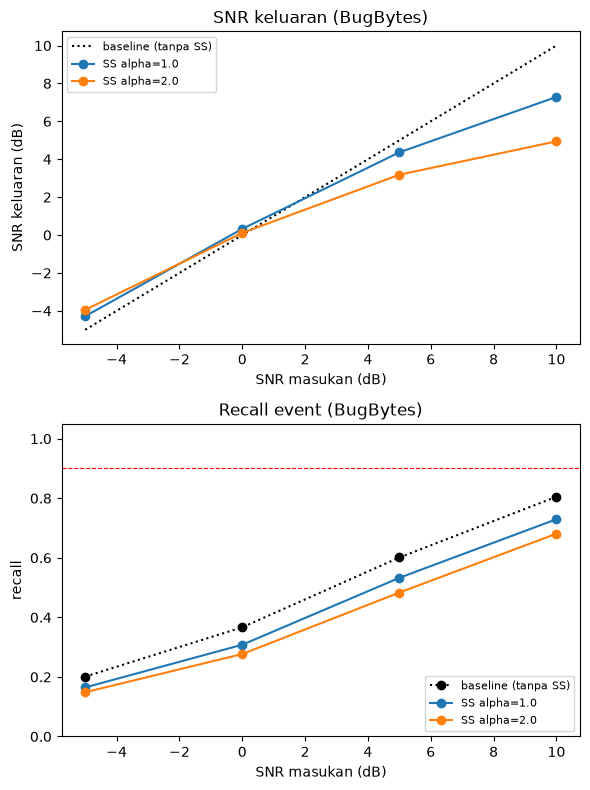

In [10]:
# ringkasan: rerata SNR keluaran dan recall/presisi per kelompok noise, SNR masukan, dan alpha
ring = (eksp.groupby(["noise_grup", "alpha", "snr_in"])           # kelompokkan hasil menurut grup noise, alpha, dan SNR masukan
        .agg(snr_ss=("snr_ss", "mean"), delta_snr=("delta_snr", "mean"), delta_sd=("delta_snr", "std"),   # rerata SNR keluaran, rerata kenaikan, dan sebarannya
             recall_base=("recall_base", "mean"), recall_ss=("recall_ss", "mean"),                         # rerata recall tanpa dan dengan SS
             presisi_base=("presisi_base", "mean"), presisi_ss=("presisi_ss", "mean"))                     # rerata presisi tanpa dan dengan SS
        .round(3).reset_index())
ring.to_csv(f"{RES}/m2_ringkasan_snr_recall.csv", index=False)
display(ring)

# kurva SNR keluaran dan recall terhadap SNR masukan, per kelompok noise
grups = list(eksp.noise_grup.unique())                            # daftar kelompok noise (BugBytes, ESC50)
fig, ax = plt.subplots(2, len(grups), figsize=(6 * len(grups), 8), squeeze=False)   # baris atas = SNR, baris bawah = recall; satu kolom per kelompok noise
for c, g in enumerate(grups):
    d = eksp[eksp.noise_grup == g]                                # data kelompok noise ini saja
    ax[0, c].plot(SNR_LIST, SNR_LIST, "k:", label="baseline (tanpa SS)")   # garis acuan y=x: tanpa SS, SNR keluaran = SNR masukan
    ax[1, c].plot(SNR_LIST, d.groupby("snr_in").recall_base.mean(), "k:", marker="o", label="baseline (tanpa SS)")   # recall baseline
    for a in ALPHAS:                                              # satu kurva per alpha
        da = d[d.alpha == a]
        ax[0, c].plot(SNR_LIST, da.groupby("snr_in").snr_ss.mean(), marker="o", label=f"SS alpha={a}")    # SNR keluaran setelah SS
        ax[1, c].plot(SNR_LIST, da.groupby("snr_in").recall_ss.mean(), marker="o", label=f"SS alpha={a}") # recall setelah SS
    ax[0, c].set(title=f"SNR keluaran ({g})", xlabel="SNR masukan (dB)", ylabel="SNR keluaran (dB)")
    ax[1, c].set(title=f"Recall event ({g})", xlabel="SNR masukan (dB)", ylabel="recall", ylim=(0, 1.05))
    ax[1, c].axhline(0.9, color="r", lw=0.8, ls="--")             # garis target recall 90%
    ax[0, c].legend(fontsize=8); ax[1, c].legend(fontsize=8)
fig.tight_layout()
fig.savefig(f"{RES}/m2_kurva_snr_recall.png", dpi=150)
plt.show(); plt.close(fig)

### Penjelasan ringkasan dan kurva
**Tabel `ring`.** Merata-ratakan semua campuran untuk tiap kombinasi *kelompok noise × alpha × SNR masukan*. Kolom `delta_snr` adalah kenaikan SNR rata-rata berkat spectral subtraction, dan `delta_sd` sebarannya.


- **Baris atas (SNR keluaran):** garis titik-titik hitam adalah acuan tanpa SS (keluaran = masukan). Kurva yang berada **di atas** garis itu berarti SS menaikkan SNR.
- **Baris bawah (recall):** proporsi event asli yang masih terdeteksi. Garis merah putus-putus menandai target **90%**.

**Kelompok noise digambar terpisah** (kolom kiri dan kanan) karena sifat spektrumnya berbeda (BugBytes hampir seluruhnya di bawah 200 Hz, ESC-50 tidak).

## Spectral subtraction: kenaikan SNR ≥ 3 dB dan recall ≥ 90% (SNR masukan ≥ 0 dB)

Tiap baris tabel = satu kombinasi kelompok noise × alpha × SNR masukan. Uji:
- **Wilcoxon satu arah**: ΔSNR > 3 dB (dan ΔSNR > 0).
- **Wilcoxon berpasangan** recall SS vs baseline (dua arah).
- `recall_ok` = rerata recall SS ≥ 0,9 (relevan untuk SNR masukan ≥ 0 dB).

Dua tingkat ulangan dilaporkan: **per potongan** (sesuai draf, n besar tapi potongan dari file yang sama tidak independen) dan **rerata per file × noise** (lebih konservatif, n kecil). Ukuran efek: rank-biserial.

## Uji Wilcoxon: kenaikan SNR dan recall spectral subtraction
*H10: uji Wilcoxon (bagian kedua dari tiga uji H10).*

In [11]:
# =====================================================================
# Uji Wilcoxon signed-rank: apakah SS benar-benar menaikkan SNR >= 3 dB dan menjaga recall >= 90%?
# =====================================================================
def wil(d, alt):
    """p-value uji Wilcoxon signed-rank untuk selisih berpasangan d.
    alt = 'greater' (satu arah: selisih > 0) atau 'two-sided' (dua arah). NaN bila data kurang dari 5 atau semuanya nol."""
    d = np.asarray(d, float); d = d[~np.isnan(d)]               # buang nilai kosong (NaN)
    if len(d) < 5 or np.all(d == 0):                            # data terlalu sedikit / tanpa selisih -> uji tidak bermakna
        return np.nan
    return stats.wilcoxon(d, alternative=alt).pvalue            # uji tanda-peringkat Wilcoxon, kembalikan p-value saja

baris = []
agg = (eksp.groupby(["noise_grup", "alpha", "snr_in", "kode", "noise_kunci"])   # tingkat konservatif: rata-ratakan 20 potongan jadi 1 angka per (file hama x noise)
       .agg(delta_snr=("delta_snr", "mean"), recall_base=("recall_base", "mean"), recall_ss=("recall_ss", "mean"))
       .reset_index())
for (g, a, sn), d in eksp.groupby(["noise_grup", "alpha", "snr_in"]):   # satu uji per kombinasi grup noise x alpha x SNR masukan
    da = agg[(agg.noise_grup == g) & (agg.alpha == a) & (agg.snr_in == sn)]   # data teragregasi untuk kombinasi yang sama
    baris.append({"noise_grup": g, "alpha": a, "snr_in": sn, "n_run": len(d), "n_agg": len(da),   # jumlah data tingkat per-potongan dan tingkat teragregasi
                  "median_delta_dB": round(d.delta_snr.median(), 2),                                # median kenaikan SNR
                  "p_delta_gt3": wil(d.delta_snr - 3, "greater"),                                    # uji: kenaikan > 3 dB? (selisih dikurangi 3, diuji > 0)
                  "rb_delta_gt3": round(rank_biserial(d.delta_snr - 3), 2),                          # ukuran efeknya
                  "p_delta_gt3_agg": wil(da.delta_snr - 3, "greater"),                               # uji yang sama pada data teragregasi (lebih ketat)
                  "p_delta_gt0": wil(d.delta_snr, "greater"),                                        # kenaikan > 0 dB (SS paling tidak membantu)?
                  "recall_base": round(d.recall_base.mean(), 3), "recall_ss": round(d.recall_ss.mean(), 3),
                  "recall_ok": bool(d.recall_ss.mean() >= 0.9),                                      # target recall 90% tercapai?
                  "p_recall_ss_vs_base": wil((d.recall_ss - d.recall_base).values, "two-sided")})    # recall SS berbeda dari baseline? (berpasangan, dua arah)
h2 = pd.DataFrame(baris)
h2.to_csv(f"{RES}/m2_h2_wilcoxon.csv", index=False)
display(h2)

# ringkasan jawaban H2 (hanya SNR masukan >= 0 dB)
sub = h2[h2.snr_in >= 0]                                        # hanya SNR masukan 0, 5, 10 dB
for (g, a), d in sub.groupby(["noise_grup", "alpha"]):
    ok_snr = (d.median_delta_dB >= 3).all() and (d.p_delta_gt3 < ALPHA_SIG).all()   # syarat SNR: median >= 3 dB di semua SNR DAN signifikan
    ok_rec = d.recall_ok.all()                                   # syarat recall: >= 90% di semua SNR
    print(f"{g:9s} alpha={a}: kenaikan SNR >=3 dB (SNR masukan >=0): {'ya' if ok_snr else 'tidak'} | recall >=90%: {'ya' if ok_rec else 'tidak'}")

,noise_grup,alpha,snr_in,n_run,n_agg,median_delta_dB,p_delta_gt3,rb_delta_gt3,p_delta_gt3_agg,p_delta_gt0,recall_base,recall_ss,recall_ok,p_recall_ss_vs_base
0,BugBytes,1.0,-5,420,21,0.54,1.0,-1.0,1.0,7.583126e-71,0.201,0.165,False,1.383024e-59
1,BugBytes,1.0,0,420,21,0.34,1.0,-1.0,1.0,1.296187e-25,0.367,0.308,False,1.048744e-66
2,BugBytes,1.0,5,420,21,-0.81,1.0,-1.0,1.0,1.000000e+00,0.601,0.533,False,4.864324e-69
3,BugBytes,1.0,10,420,21,-3.38,1.0,-1.0,1.0,1.000000e+00,0.805,0.730,False,7.538735e-68
4,BugBytes,2.0,-5,420,21,0.79,1.0,-1.0,1.0,1.319769e-69,0.201,0.149,False,1.173001e-61
5,BugBytes,2.0,0,420,21,0.01,1.0,-1.0,1.0,7.332367e-02,0.367,0.277,False,1.945047e-68
6,BugBytes,2.0,5,420,21,-2.23,1.0,-1.0,1.0,1.000000e+00,0.601,0.483,False,7.955401e-70
7,BugBytes,2.0,10,420,21,-6.19,1.0,-1.0,1.0,1.000000e+00,0.805,0.681,False,2.264510e-69


BugBytes  alpha=1.0: kenaikan SNR >=3 dB (SNR masukan >=0): tidak | recall >=90%: tidak
BugBytes  alpha=2.0: kenaikan SNR >=3 dB (SNR masukan >=0): tidak | recall >=90%: tidak


### Penjelasan uji Wilcoxon
**Pertanyaan.** Apakah spectral subtraction menaikkan SNR **lebih dari 3 dB** dan mempertahankan **recall ≥ 90%** (untuk SNR masukan ≥ 0 dB)?

**Mengapa Wilcoxon signed-rank.** Data berpasangan (sebelum vs sesudah SS pada campuran yang sama) dan tidak diasumsikan normal. Uji ini bekerja pada selisih berpasangan.

**Cara menguji “> 3 dB”.** Selisih `delta_snr` dikurangi 3 lalu diuji apakah lebih besar dari 0 (uji satu arah). Uji kedua (`p_delta_gt0`) hanya memeriksa apakah SS membantu sama sekali.

**Dua tingkat ulangan**
- **Per potongan** (`p_delta_gt3`): n besar, tetapi potongan dari file yang sama tidak sepenuhnya independen.
- **Rerata per file × noise** (`p_delta_gt3_agg`): n kecil tetapi lebih konservatif.

**Ukuran efek.** `rank_biserial` (−1 sampai +1) menunjukkan seberapa konsisten selisihnya.

**Kesimpulan otomatis** di akhir sel menyatakan, per kelompok noise dan alpha, apakah dua syarat (kenaikan SNR ≥ 3 dB dan recall ≥ 90%) terpenuhi pada semua SNR masukan ≥ 0 dB.

##  Jumlah getaran naik seiring kepadatan serangga (CSV USDA)



##  Memuat CSV getaran USDA


In [15]:
# =====================================================================
# Memuat CSV getaran USDA (Beetle Vibration Data) dan menebak kolom pentingnya
# =====================================================================
GETARAN = "../data/getaran"                                  # folder data getaran USDA
USDA_CSV = f"{GETARAN}/Beetle Vibration Data.csv"            # path langsung ke CSV (spasi di nama file tidak masalah)
USDA_KEY = f"{GETARAN}/Beetle_Vibration_Data_Key.txt"        # berkas kunci: penjelasan arti tiap kolom
COL_SPESIES = COL_KEPADATAN = COL_REKAMAN = COL_JUMLAH = None   # isi manual bila tebakan salah

# tampilkan isi berkas kunci supaya arti kolom langsung terlihat
if os.path.exists(USDA_KEY):
    print(open(USDA_KEY, encoding="utf-8", errors="ignore").read())
else:
    print("[!] berkas kunci tidak ditemukan:", USDA_KEY)

usda = None
if os.path.exists(USDA_CSV):
    usda = pd.read_csv(USDA_CSV)                             # baca CSV jadi tabel
    print("file:", os.path.basename(USDA_CSV), usda.shape)   # nama file dan ukuran (baris, kolom)
    print("kolom:", list(usda.columns))                      # daftar nama kolom
    display(usda.head())                                     # lima baris pertama
    def tebak(pola):
        """Mencari nama kolom pertama yang cocok dengan pola regex; None bila tak ada."""
        c = [k for k in usda.columns if re.search(pola, str(k), re.I)]
        return c[0] if c else None
    print("tebakan -> spesies:", tebak("spec|species|spesies|pest"),
          "| kepadatan:", tebak("dens|kg|infest|level"),
          "| rekaman:", tebak("file|record|sample|trial|rep|id"))
else:
    print("[!] CSV USDA tidak ditemukan:", USDA_CSV)

Beetle Vibration Column Descriptions
Trial: Identifies the trial block (A-U) in which each recording was conducted.
Species: Abbreviated scientific name for each beetle species
	R. dominica = Rhyzopertha dominica
	S. zeamais = Sitophilus zeamais
	T. castaneum = Tribolium castaneum
Density: The proportional density of insects in the grain mass (units = insects per kilogram). 
Av_Int: The mean interval (seconds) between vibration pulses 
Av_Dur: The mean duration (seconds) of each vibration pulse
Count: The total number of vibration pulses in each recording
Freq: The mean peak frequency (kHz) of each vibration pulse
ID: The individual name given to each observation
logInt: The log transformation of Av_Int
logCount: The log transformation of Count
logDur: The log transformation of Av_Dur
	

file: Beetle Vibration Data.csv (159, 12)
kolom: ['Unnamed: 0', 'Trial', 'Species', 'Density', 'Av_Int', 'Av_Dur', 'Count', 'Freq', 'ID', 'logInt', 'logCount', 'logDur']


,Unnamed: 0,Trial,Species,Density,Av_Int,Av_Dur,Count,Freq,ID,logInt,logCount,logDur
0,2,A,R. dominica,20,0.870756,0.001868,49,5.561719,A LGB 4,-0.060104,1.690196,-2.728679
1,3,A,R. dominica,40,0.001315,0.001572,6,5.390479,A LGB 8,-2.881006,0.778151,-2.803492
2,4,A,T. castaneum,5,0.116803,0.002825,208,5.380402,A RFB 1,-0.932548,2.318063,-2.548963
3,5,A,T. castaneum,20,0.163637,0.002128,849,4.313387,A RFB 4,-0.786119,2.928908,-2.671981
4,6,A,T. castaneum,40,0.125332,0.002267,1078,4.362691,A RFB 8,-0.901938,3.032619,-2.644619


tebakan -> spesies: Species | kepadatan: Density | rekaman: Trial


### Penjelasan memuat CSV USDA


##  Kruskal–Wallis dan Spearman pada CSV USDA
*H10: uji Spearman (bagian ketiga dari tiga uji H10) bersama Kruskal–Wallis antar kepadatan.*

In [16]:
# =====================================================================
# Apakah jumlah getaran per rekaman naik seiring kepadatan serangga? (Kruskal-Wallis + Spearman)
# =====================================================================
if usda is None:                                                  # CSV belum dimuat -> lewati
    print("[!] CSV USDA belum dimuat: H3 dilewati")
else:
    def tebak(pola):
        """Mencari nama kolom pertama yang cocok dengan pola regex; None bila tak ada."""
        c = [k for k in usda.columns if re.search(pola, str(k), re.I)]
        return c[0] if c else None
    cs = COL_SPESIES or tebak("spec|species|spesies|pest")        # kolom spesies: pilihan manual, kalau kosong pakai tebakan
    ck = COL_KEPADATAN or tebak("dens|kg|infest|level")           # kolom kepadatan
    cr = COL_REKAMAN or tebak("file|record|sample|trial|rep|id")  # kolom identitas rekaman
    print("kolom dipakai -> spesies:", cs, "| kepadatan:", ck, "| rekaman:", cr, "| jumlah:", COL_JUMLAH)
    d = usda.copy()                                               # salinan agar tabel asli tidak berubah
    d["kepadatan"] = pd.to_numeric(d[ck].astype(str).str.extract(r"(\d+(?:\.\d+)?)")[0], errors="coerce")   # ambil angka dari teks kepadatan (mis. "5 insects/kg" -> 5.0)
    d["spesies_usda"] = d[cs].astype(str) if cs else "semua"      # label spesies; "semua" bila tidak ada kolom spesies
    if COL_JUMLAH:                                                # kasus 1: CSV sudah berisi kolom jumlah getaran
        per_rek = d.rename(columns={COL_JUMLAH: "jumlah"})[["spesies_usda", "kepadatan", "jumlah"]]
    elif cr:                                                      # kasus 2: jumlah = banyaknya baris (getaran) per rekaman
        per_rek = d.groupby(["spesies_usda", "kepadatan", cr]).size().rename("jumlah").reset_index()
    else:                                                         # kasus 3: tidak ada informasi rekaman -> tidak bisa dilanjutkan
        per_rek = None
        print("[!] kolom rekaman tidak ditemukan: isi COL_REKAMAN atau COL_JUMLAH")
    if per_rek is not None:
        per_rek = per_rek.dropna(subset=["kepadatan"])            # buang baris yang kepadatannya tak terbaca
        per_rek.to_csv(f"{RES}/m2_h3_jumlah_per_rekaman.csv", index=False)
        baris = []
        for sp_, g in list(per_rek.groupby("spesies_usda")) + [("SEMUA", per_rek)]:   # uji per spesies, lalu gabungan semua spesies
            lv = [x["jumlah"].values for _, x in g.groupby("kepadatan") if len(x) >= 2]   # jumlah getaran per tingkat kepadatan (minimal 2 rekaman)
            if len(lv) < 2:                                       # perlu minimal 2 tingkat kepadatan
                continue
            H, pk = stats.kruskal(*lv)                            # Kruskal-Wallis: apakah jumlah getaran berbeda antar tingkat kepadatan?
            rho, ps = stats.spearmanr(g["kepadatan"], g["jumlah"], alternative="greater")   # Spearman satu arah: apakah jumlah NAIK seiring kepadatan? (rho = korelasi peringkat)
            baris.append({"spesies": sp_, "n_rekaman": len(g), "n_level": len(lv),
                          "median_per_level": {k: float(v["jumlah"].median()) for k, v in g.groupby("kepadatan")},   # median jumlah getaran di tiap level
                          "KW_H": round(H, 2), "KW_p": pk, "spearman_rho": round(rho, 3), "spearman_p_greater": ps,
                          "naik_signifikan": bool(ps < ALPHA_SIG)})   # True bila tren naik signifikan
        h3 = pd.DataFrame(baris)
        h3.to_csv(f"{RES}/m2_h3_kruskal_spearman.csv", index=False)
        display(h3)

kolom dipakai -> spesies: Species | kepadatan: Density | rekaman: Trial | jumlah: None


c:\Users\User\miniconda3\envs\semesterlima\Lib\site-packages\scipy\stats\_stats_py.py:8674: RuntimeWarning: invalid value encountered in scalar divide
  h /= ties
C:\Users\User\AppData\Local\Temp\ipykernel_13768\3410125258.py:34: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, ps = stats.spearmanr(g["kepadatan"], g["jumlah"], alternative="greater")   # Spearman satu arah: apakah jumlah NAIK seiring kepadatan? (rho = korelasi peringkat)
c:\Users\User\miniconda3\envs\semesterlima\Lib\site-packages\scipy\stats\_stats_py.py:8674: RuntimeWarning: invalid value encountered in scalar divide
  h /= ties
C:\Users\User\AppData\Local\Temp\ipykernel_13768\3410125258.py:34: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, ps = stats.spearmanr(g["kepadatan"], g["jumlah"], alternative="greater")   # Spearman satu arah: apakah jumlah NAIK seiring kepadatan? (rho = korelasi peringkat)
c:\Users\User\

,spesies,n_rekaman,n_level,median_per_level,KW_H,KW_p,spearman_rho,spearman_p_greater,naik_signifikan
0,R. dominica,45,3,"{5: 1.0, 20: 1.0, 40: 1.0}",NaN,NaN,NaN,NaN,False
1,S. zeamais,55,3,"{5: 1.0, 20: 1.0, 40: 1.0}",NaN,NaN,NaN,NaN,False
2,T. castaneum,59,3,"{5: 1.0, 20: 1.0, 40: 1.0}",NaN,NaN,NaN,NaN,False
3,SEMUA,159,3,"{5: 1.0, 20: 1.0, 40: 1.0}",NaN,NaN,NaN,NaN,False


In [17]:
# Checklist otomatis: tampilkan tanda centang bila file keluaran tiap capaian sudah ada
def tanda(ok): return "✓" if ok else "✗"                          # ✓ = ada/benar, ✗ = belum
ada = lambda f: os.path.exists(f"{RES}/{f}")                      # True bila file f sudah ada di folder results
print(tanda(ada("m2_profil_per_file.csv") and ada("m2_spektrum_per_file.png")), "Profil RMS dan spektrum per spesies dan sensor")
print(tanda(ada("m2_h1_kruskal.csv")), "Kruskal–Wallis (+Dunn) H1")
ok_mix = ("eksp" in globals()) and set(SNR_LIST) == set(eksp.snr_in.unique()) and eksp.potongan.nunique() == N_POTONG   # eksperimen sudah jalan, memuat 4 SNR dan 20 potongan
print(tanda(ok_mix), f"{len(SNR_LIST)} SNR × {N_POTONG} campuran")
print(tanda(ada("m2_hasil_eksperimen.csv")), "Spectral subtraction dijalankan (hasil per campuran tersimpan)")
print(tanda(ada("m2_h2_wilcoxon.csv")), "Wilcoxon SNR (H2)")
print(tanda(ada("m2_h3_kruskal_spearman.csv")), "Kruskal–Wallis dan Spearman CSV USDA (H3)")
print(tanda(ada("m2_daftar_file_noise.csv") and ada("m2_parameter.json")), "Daftar file noise dan parameter tersimpan (reproduksibilitas)")

✓ Profil RMS dan spektrum per spesies dan sensor
✓ Kruskal–Wallis (+Dunn) H1
✓ 4 SNR × 20 campuran
✓ Spectral subtraction dijalankan (hasil per campuran tersimpan)
✓ Wilcoxon SNR (H2)
✓ Kruskal–Wallis dan Spearman CSV USDA (H3)
✓ Daftar file noise dan parameter tersimpan (reproduksibilitas)
